# 04 — ERF trên 2.000 ảnh cân bằng lớp

So sánh ResNet-50 và ViT-B/16 trên **2.000 ảnh = 2 ảnh/lớp × 1.000 lớp**, chọn cố định
từ manifest 10.000 ảnh của nhóm, seed 42. Cùng cohort dùng cho official và shared_vit_crop;
không lọc theo dự đoán đúng/sai. Đây là subset mới, không dùng kết quả 100 ảnh thay thế.

Toàn bộ code ERF và thống kê nằm trong notebook; không cần script thống kê/kiểm tra riêng.
Project trên Drive vẫn cần các module chung src.models, src.data và dữ liệu đã chuẩn bị.

**Thứ tự:** Bước 0–5 → smoke test một ảnh ở Bước 6 → official ở Bước 7 → xác minh Bước 8a →
shared_vit_crop ở Bước 8b → kiểm định/bảng/biểu đồ ở Bước 8c.
Mỗi lượt đầy đủ có **16.000 dòng metrics**; mỗi phép kiểm định có **2.000 cặp ảnh**.
Notebook chưa chạy, không lưu output cũ hoặc số liệu 2.000 ảnh giả.

Muốn nạp lại run complete: điền đường dẫn .../final/ vào OFFICIAL_RUN_DIR (Bước 7)
hoặc SHARED_RUN_DIR (Bước 8b). Chưa có resume run bị ngắt; checkpoint chỉ giữ phần đã tính.

## Lý do chọn 2.000 ảnh

**Mục tiêu:** giảm độ bất định của chênh lệch ERF trung bình, đồng thời phủ đủ 1.000 lớp
trong giới hạn tài nguyên. Đây là lựa chọn thiết kế cho subset, không phải số ảnh bắt buộc
do đề bài quy định. Tập phân tích chung đầy đủ của nhóm vẫn là 10.000 ảnh.

**Căn cứ pilot:** bảng ghép cặp trong 04_erf_100.ipynb có độ lệch chuẩn lớn nhất của
hiệu số A90 ViT − ResNet ở chế độ official là **11,127155 điểm phần trăm**.
Dùng công thức lập kế hoạch xấp xỉ cho biên CI 95% của trung bình:

$$h \approx 1.96\,s_d/\sqrt{N},\qquad N\approx(1.96\,s_d/h)^2.$$

Chọn trước mục tiêu h = 0,5 điểm phần trăm:
N ≈ (1,96 × 11,127155 / 0,5)² ≈ 1902,5, làm tròn lên **1.903** rồi chọn **2.000 ảnh**.
Biên dự kiến khoảng **±0,488 điểm phần trăm**, so với ±2,181 ở 100 ảnh.
Nguồn: [NIST — Confidence Limits for the Mean](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm).

**Cân bằng lớp:** chọn ngẫu nhiên không hoàn lại 2 trong 10 ảnh mỗi lớp từ manifest đã chốt,
seed 42, duyệt lớp 0–999; không lấy 2.000 dòng đầu. Mỗi lớp có trọng số bằng nhau
trong trung bình toàn cohort. Chỉ 2 ảnh/lớp chưa đủ suy luận riêng cho từng lớp.

**Giới hạn:** phép tính dựa vào pilot A90 official, không bảo đảm CI thực tế đạt ±0,5,
không phải power analysis cho Wilcoxon, không bảo đảm độ chính xác của dispersion/shared crop.
Pilot lấy mẫu đều theo ảnh còn lượt này cân bằng lớp nên phương sai có thể khác.
Phải tính CI thực tế từ số liệu mới; CI riêng từng so sánh chưa hiệu chỉnh đa kiểm định.
p-value được hiệu chỉnh Holm cho 16 phép kiểm định. Không tăng N chỉ để đạt p < 0,05.

**Tiền lệ trực quan hóa:** Figure 6, trang 6 của
[Raghu et al., NeurIPS 2021](https://proceedings.neurips.cc/paper_files/paper/2021/file/652cf38361a209088302ba2b8b7f51e0-Paper.pdf#page=6)
dùng 32 ảnh chọn ngẫu nhiên để minh họa ERF. Đây là tiền lệ cho khảo sát định tính,
không chứng minh một số ảnh cụ thể đủ cho các metric/kiểm định của notebook này.

## Bước 0 — Kiểm tra nơi chạy

Trên [Google Colab](https://colab.research.google.com/), chọn **File → Upload notebook**,
mở file này, rồi vào **Runtime → Change runtime type → chọn GPU** nếu được cấp.
Chạy ô dưới. `CUDA: True` nghĩa là PyTorch nhìn thấy GPU.
`False` vẫn chạy thử được bằng CPU, nhưng hãy kiểm tra lại runtime trước khi chạy nhiều ảnh.

Colab thường có sẵn torch/torchvision. Nếu thiếu thư viện phụ, ô này cài vào đúng kernel.
Khi dùng máy cá nhân, cài bộ torch/torchvision phù hợp theo
[hướng dẫn PyTorch](https://pytorch.org/get-started/locally/) trước.

In [2]:
import importlib.util
import subprocess
import sys

missing = [package for package in ['numpy', 'pandas', 'matplotlib', 'PIL', 'pyarrow', 'tqdm', 'scipy']
           if importlib.util.find_spec(package) is None]
if missing:
    packages = ['pillow' if name == 'PIL' else name for name in missing]
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *packages])

import torch
import torchvision

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('CUDA:', torch.cuda.is_available())
print('Thiết bị:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU')

Python: 3.13.16
PyTorch: 2.11.0+cu130 | torchvision: 0.26.0+cu130
CUDA: True
Thiết bị: Tesla T4


In [3]:
from collections import Counter
import hashlib
import json
from pathlib import Path
import random
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from tqdm.auto import tqdm

LAYERS = {
    "resnet50": ["layer1", "layer2", "layer3", "layer4"],
    "vit_b_16": ["block3", "block6", "block9", "block12"],
}

In [4]:
"""Phân tích ghép cặp tích hợp trực tiếp trong notebook ERF 2.000 ảnh."""

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy.stats import wilcoxon


ERF_METRICS = {
    "area90_fraction": (100.0, "percentage points"),
    "dispersion_normalized": (1.0, "normalized-coordinate RMS distance"),
}
ERF_STAGE_LAYERS = {
    "resnet50": {1: "layer1", 2: "layer2", 3: "layer3", 4: "layer4"},
    "vit_b_16": {1: "block3", 2: "block6", 3: "block9", 4: "block12"},
}


def validate_erf_metrics(metrics, records):
    """Require every selected image/model/stage exactly once; never drop pairs."""
    required = {"image_id", "dataset_index", "label", "model", "stage", "layer",
                *ERF_METRICS}
    if not required.issubset(metrics.columns):
        raise ValueError(f"Missing metrics columns: {sorted(required - set(metrics.columns))}")
    selected = pd.DataFrame(records)[["image_id", "dataset_index", "label"]]
    if selected.empty or selected.isna().any().any():
        raise ValueError("Selected records must be nonempty and complete.")
    if not selected.image_id.is_unique or not selected.dataset_index.is_unique:
        raise ValueError("Selected image IDs and dataset indices must be unique.")
    keys = ["image_id", "model", "stage"]
    expected = pd.MultiIndex.from_tuples(
        [(row["image_id"], model, stage) for row in records
         for model, layers in ERF_STAGE_LAYERS.items() for stage in layers], names=keys,
    )
    actual = pd.MultiIndex.from_frame(metrics[keys])
    if not actual.is_unique or set(actual) != set(expected):
        raise ValueError("Expected exactly one row per selected image/model/stage (8 x N).")
    joined = metrics.merge(selected, on="image_id", suffixes=("", "_selected"),
                           validate="many_to_one")
    for column in ["dataset_index", "label"]:
        if not joined[column].eq(joined[f"{column}_selected"]).all():
            raise ValueError(f"Metrics {column} differs from selected images.")
    for model, layers in ERF_STAGE_LAYERS.items():
        group = metrics[metrics.model == model]
        if not group.layer.eq(group.stage.map(layers)).all():
            raise ValueError(f"Layer/stage mismatch for {model}.")
    for metric in ERF_METRICS:
        values = metrics[metric].to_numpy(dtype=float)
        if not np.isfinite(values).all() or (values < 0).any() or (values > 1).any():
            raise ValueError(f"Invalid or missing {metric} values.")
    return metrics


def load_completed_erf_run(directory, records, preprocessing, seed=42):
    """Read a completed run only if its selection, checksum and settings match."""
    directory = Path(directory)
    metadata_path = directory / "metadata.json"
    if not metadata_path.is_file():
        metadata_path = directory / "run.json"  # Legacy official runs.
    metadata = json.loads(metadata_path.read_text("utf-8"))
    if (metadata.get("status") != "complete"
            or metadata.get("num_images") != len(records)
            or metadata.get("preprocessing") != preprocessing
            or metadata.get("seed") != seed):
        raise ValueError(f"Incomplete run or incompatible settings: {directory}")
    selection_path = directory / "selected_images.csv"
    if hashlib.sha256(selection_path.read_bytes()).hexdigest() != metadata.get("selected_images_sha256"):
        raise ValueError("Saved selection checksum does not match metadata.")
    columns = ["image_id", "dataset_index", "label"]
    saved = pd.read_csv(selection_path)[columns].sort_values("image_id").reset_index(drop=True)
    wanted = pd.DataFrame(records)[columns].sort_values("image_id").reset_index(drop=True)
    pd.testing.assert_frame_equal(saved, wanted, check_dtype=False)
    metrics = pd.read_csv(directory / "metrics.csv")
    validate_erf_metrics(metrics, records)
    return metrics, metadata


def validate_erf_run_pair(official_metadata, shared_metadata):
    """The only intended experimental change is preprocessing."""
    for key in ["target", "center_rule", "gradient_coordinates", "layers", "seed", "num_images",
                "selection_rule", "cohort_sha256_lf"]:
        if key not in official_metadata or official_metadata[key] != shared_metadata.get(key):
            raise ValueError(f"Runs differ in {key}; cannot attribute changes to preprocessing.")
    for model in ERF_STAGE_LAYERS:
        before = official_metadata["models"][model]
        after = shared_metadata["models"][model]
        if before["weights"] != after["weights"]:
            raise ValueError(f"Model weights differ: {model}")
    shared_models = shared_metadata["models"]
    if shared_models["resnet50"]["transform"] != shared_models["vit_b_16"]["transform"]:
        raise ValueError("shared_vit_crop must use identical transforms for both models.")
    if official_metadata["models"]["vit_b_16"]["transform"] != shared_models["vit_b_16"]["transform"]:
        raise ValueError("ViT preprocessing should be unchanged between the two runs.")


def paired_erf_differences(metrics, records, preprocessing):
    """Align by image ID and stage, independent of CSV/loader row order."""
    validate_erf_metrics(metrics, records)
    frames = []
    for metric, (scale, unit) in ERF_METRICS.items():
        paired = metrics.pivot(index=["image_id", "stage"], columns="model", values=metric)
        paired = paired.sort_index().reset_index()
        paired = paired.merge(pd.DataFrame(records)[["image_id", "dataset_index", "label"]],
                              on="image_id", validate="many_to_one")
        paired["difference"] = (paired["vit_b_16"] - paired["resnet50"]) * scale
        paired["metric"], paired["unit"], paired["preprocessing"] = metric, unit, preprocessing
        frames.append(paired)
    return pd.concat(frames, ignore_index=True)


def bootstrap_mean_ci(differences, seed=42, n_resamples=20000):
    """Resample images/pairs, not the two model columns separately."""
    values = np.asarray(differences, dtype=float)
    if values.ndim != 1 or len(values) < 2 or not np.isfinite(values).all():
        raise ValueError("Bootstrap requires at least two finite paired differences.")
    if not isinstance(n_resamples, (int, np.integer)) or n_resamples < 1000:
        raise ValueError("Use at least 1,000 bootstrap resamples.")
    rng = np.random.default_rng(seed)
    means = np.empty(n_resamples)
    for start in range(0, n_resamples, 1000):
        stop = min(start + 1000, n_resamples)
        indices = rng.integers(0, len(values), size=(stop - start, len(values)))
        means[start:stop] = values[indices].mean(axis=1)
    return np.quantile(means, [0.025, 0.975])


def holm_adjust(pvalues):
    """Holm family-wise error correction, preserving the original row order."""
    pvalues = np.asarray(pvalues, dtype=float)
    if pvalues.ndim != 1 or not np.isfinite(pvalues).all() or ((pvalues < 0) | (pvalues > 1)).any():
        raise ValueError("P-values must be finite numbers in [0, 1].")
    order = np.argsort(pvalues, kind="stable")
    adjusted = np.empty_like(pvalues)
    adjusted[order] = np.minimum(1, np.maximum.accumulate(
        pvalues[order] * np.arange(len(pvalues), 0, -1)))
    return adjusted


def paired_erf_tests(pairs, seed=42, n_resamples=20000):
    """Two-sided signed-rank tests; bootstrap mean CIs are separate estimates."""
    rows = []
    for group_index, ((mode, metric, stage), group) in enumerate(
        pairs.groupby(["preprocessing", "metric", "stage"], sort=True)
    ):
        group = group.sort_values("image_id")
        if not group.image_id.is_unique:
            raise ValueError("Duplicate image in a paired comparison.")
        delta = group.difference.to_numpy(dtype=float)
        low, high = bootstrap_mean_ci(delta, seed + group_index, n_resamples)
        # Round subtraction noise consistently; zeros are excluded by Wilcoxon.
        signed_rank_delta = np.round(delta, 12)
        nonzero = np.count_nonzero(signed_rank_delta)
        if nonzero == 0:
            statistic, pvalue = 0.0, 1.0
        else:
            result = wilcoxon(signed_rank_delta, zero_method="wilcox",
                              alternative="two-sided", method="auto")
            statistic, pvalue = float(result.statistic), float(result.pvalue)
        rows.append({
            "preprocessing": mode, "metric": metric, "stage": int(stage),
            "resnet_layer": ERF_STAGE_LAYERS["resnet50"][stage],
            "vit_layer": ERF_STAGE_LAYERS["vit_b_16"][stage],
            "n_pairs": len(delta), "n_nonzero_wilcoxon": int(nonzero),
            "unit": group.unit.iloc[0],
            "resnet_mean": group.resnet50.mean() * ERF_METRICS[metric][0],
            "vit_mean": group.vit_b_16.mean() * ERF_METRICS[metric][0],
            "mean_difference": delta.mean(), "median_difference": np.median(delta),
            "sd_difference": delta.std(ddof=1),
            "mean_ci95_low": low, "mean_ci95_high": high,
            "wilcoxon_statistic": statistic, "p_value": pvalue,
        })
    tests = pd.DataFrame(rows)
    if tests.empty:
        raise ValueError("No paired comparisons supplied.")
    # One family: 2 preprocessing modes x 2 metrics x 4 relative stages = 16.
    tests["p_holm"] = holm_adjust(tests.p_value)
    tests["reject_holm_0_05"] = tests.p_holm < 0.05
    return tests


def erf_crop_sensitivity(pairs, seed=42, n_resamples=20000):
    """Descriptive CI for change in the ViT-minus-ResNet gap on the same images."""
    wide = pairs.pivot(index=["image_id", "metric", "stage", "unit"],
                       columns="preprocessing", values="difference")
    if set(wide.columns) != {"official", "shared_vit_crop"} or wide.isna().any().any():
        raise ValueError("Both preprocessing modes must contain exactly the same image pairs.")
    wide["gap_change"] = wide.shared_vit_crop - wide.official
    rows = []
    for index, ((metric, stage, unit), group) in enumerate(wide.reset_index().groupby(
        ["metric", "stage", "unit"], sort=True
    )):
        group = group.sort_values("image_id")
        delta = group.gap_change.to_numpy()
        low, high = bootstrap_mean_ci(delta, seed + index, n_resamples)
        rows.append({"metric": metric, "stage": int(stage), "unit": unit,
                     "n_pairs": len(delta), "official_gap_mean": group.official.mean(),
                     "shared_gap_mean": group.shared_vit_crop.mean(),
                     "gap_change_mean": delta.mean(), "mean_ci95_low": low,
                     "mean_ci95_high": high})
    return pd.DataFrame(rows)

## Bước 1 — Project và dữ liệu của nhóm

Project trên Drive cần src/models.py, src/data.py, src/evaluation.py, src/evaluate_baseline.py,
manifest/config và đủ 14 shard validation. Không cần upload lại module nếu đã cập nhật
ở lượt 100 ảnh. Đặt PROJECT_ROOT đúng project; có thể đổi DATA_DIR sang bản copy runtime
khi Drive đọc chậm, nhưng giữ kết quả trên Drive.

ALLOW_DOWNLOAD = True cho phép shared loader tải đúng checkpoint khi cache trống;
weights có sẵn vẫn được dùng lại. Có thể đổi False nếu chỉ muốn đọc cache.
Không thay checkpoint, dùng DEFAULT aliases hoặc normalize hai lần.

CHECKPOINT_EVERY = 50 giảm số lần ghi CSV lên Drive. SAVE_RAW_MAPS = False chỉ lưu
raw maps của preview vào intermediate/; metrics vẫn được tính cho đủ 2.000 ảnh.

In [5]:
IS_COLAB = importlib.util.find_spec('google.colab') is not None if importlib.util.find_spec('google') else False
if IS_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
if IS_COLAB:
    PROJECT_ROOT = Path('/content/drive/MyDrive/cnn-vit-interpretability')
else:
    PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                         if (p / 'configs/analysis_set.json').is_file()), None)
    if PROJECT_ROOT is None:
        raise FileNotFoundError('Mở notebook từ repo hoặc sửa PROJECT_ROOT bằng đường dẫn đầy đủ.')

DATA_DIR = PROJECT_ROOT / 'data/imagenet/data'
# Cập nhật các module chung trong thư mục project trên Drive trước khi chạy.
required_shared = ['src/models.py', 'src/data.py', 'src/evaluation.py', 'docs/experiment_protocol.md']
missing_shared = [name for name in required_shared if not (PROJECT_ROOT / name).is_file()]
if missing_shared:
    raise FileNotFoundError(f'Project chưa có cập nhật main: {missing_shared}. Đồng bộ repo rồi chạy lại.')
sys.path.insert(0, str(PROJECT_ROOT))
OUTPUT_BASE = PROJECT_ROOT / 'results/metrics/experiments/erf'
FIGURE_BASE = PROJECT_ROOT / 'results/figures/experiments/erf'
# Dùng cache nếu có; cho phép tải checkpoint chính thức nếu cache Colab trống.
ALLOW_DOWNLOAD = True
CHECKPOINT_EVERY = 50
SAVE_RAW_MAPS = False  # Lưu raw maps preview, không lưu full cho mọi ảnh.
print('Project:', PROJECT_ROOT)
print('Số shard validation:', len(list(DATA_DIR.glob('validation-*.parquet'))), '/ 14')
print('Config:', (PROJECT_ROOT / 'configs/analysis_set.json').is_file())
print('Manifest:', (PROJECT_ROOT / 'data/manifests/analysis_10000_seed42.csv').is_file())

Project: /content/drive/MyDrive/cnn-vit-interpretability
Số shard validation: 14 / 14
Config: True
Manifest: True


## Bước 2 — Chọn cố định 2 ảnh/lớp

Xác minh checksum và toàn manifest 10.000 ảnh qua loader chung. Duyệt lớp 0–999,
sắp ID tăng dần trong mỗi lớp rồi lấy ngẫu nhiên không hoàn lại 2 ảnh bằng
một generator random.Random(42). Sau đó sắp theo dataset index để đọc thuận tiện.

Kỳ vọng: **2.000 ID duy nhất, đủ 1.000 lớp, đúng 2 ảnh/lớp**. Cùng danh sách dùng
cho hai model và hai chế độ crop. Cohort mới không mặc định chứa mọi ảnh pilot cũ.

In [7]:
# These imports run after PROJECT_ROOT is added to sys.path in the notebook.
from src.models import load_model
from src.data import load_analysis_manifest, iter_analysis_images



def select_records(project_root, num_images=2000, seed=42):
    """Validate the shared manifest; draw exactly two images per class."""
    root = Path(project_root)
    config = json.loads((root / "configs/analysis_set.json").read_text("utf-8"))
    manifest = root / config["manifest"]
    normalized = manifest.read_bytes().replace(b"\r\n", b"\n")
    if hashlib.sha256(normalized).hexdigest() != config["manifest_sha256"]:
        raise ValueError("Analysis manifest checksum differs from the shared config.")
    full = load_analysis_manifest(manifest)
    if (config["num_classes"], config["images_per_class"], config["num_images"]) != (1000, 10, 10000):
        raise ValueError("Expected the shared 10,000-image manifest, 1,000 classes, 10/class.")
    if type(num_images) is not int or num_images != 2000:
        raise ValueError("This notebook fixes 2,000 images: 2 per class x 1,000 classes.")
    grouped = {label: [] for label in range(1000)}
    for record in full:
        grouped[record["label"]].append(record)
    rng = random.Random(seed)
    selected = []
    for label in range(1000):
        candidates = sorted(grouped[label], key=lambda row: row["image_id"])
        if len(candidates) != 10:
            raise ValueError(f"Expected 10 source images for class {label}.")
        selected.extend(rng.sample(candidates, 2))
    selected.sort(key=lambda row: row["dataset_index"])
    validate_selected_cohort(selected)
    return selected


def validate_selected_cohort(records):
    """Require the fixed balanced 2,000-image study cohort."""
    counts = Counter(row["label"] for row in records)
    if (len(records) != 2000 or counts != Counter({label: 2 for label in range(1000)})
            or len({row["image_id"] for row in records}) != 2000
            or len({row["dataset_index"] for row in records}) != 2000):
        raise ValueError("Expected 2,000 unique images, exactly 2 for each label 0..999.")
    return counts


def load_images(data_dir, records):
    """Adapt the shared RGB iterator to ERF; consume fully to validate missing IDs."""
    records = list(records)
    wanted = {row["image_id"]: row for row in records}
    if not wanted or len(wanted) != len(records):
        raise ValueError("Provide nonempty unique image IDs.")
    for image, label, image_id in iter_analysis_images(records, data_dir=data_dir):
        record = wanted[image_id]
        if label != record["label"]:
            raise ValueError(f"Label mismatch: {image_id}")
        yield record, image


def erf_output_paths(project_root, run_id):
    """Return protocol-compliant metrics, figures, and ignored intermediates."""
    if not run_id or Path(run_id).name != run_id or any(c in run_id for c in '/\\') or run_id in {'.', '..'}:
        raise ValueError("run_id must be a single nonempty directory name.")
    root = Path(project_root)
    run_root = root / "results/metrics/experiments/erf" / run_id
    return (run_root / "final",
            root / "results/figures/experiments/erf" / run_id / "final",
            run_root / "intermediate")


def erf_code_provenance(project_root):
    root = Path(project_root)
    def git_output(*arguments):
        try:
            return subprocess.check_output(["git", "-C", str(root), *arguments],
                                           stderr=subprocess.DEVNULL, text=True).strip()
        except (OSError, subprocess.CalledProcessError):
            return None
    revision = git_output("rev-parse", "HEAD")
    status = git_output("status", "--porcelain", "--untracked-files=normal")
    # Drive may contain a file copy without .git; record unknown explicitly.
    files = ["notebooks/04_erf_2000.ipynb", "src/evaluate_baseline.py",
             "src/models.py", "src/data.py", "src/evaluation.py"]
    return {"git_revision": revision, "git_dirty": None if status is None else bool(status),
            "file_sha256": {name: hashlib.sha256((root / name).read_bytes()).hexdigest()
                            for name in files if (root / name).is_file()}}

In [8]:
SEED = 42
NUM_CLASSES = 1000
IMAGES_PER_CLASS = 2
NUM_IMAGES = NUM_CLASSES * IMAGES_PER_CLASS
PREPROCESSING = 'official'
records = select_records(PROJECT_ROOT, NUM_IMAGES, SEED)
class_counts = validate_selected_cohort(records)
display(pd.DataFrame(records))
print('Số ảnh:', len(records), '| Số lớp:', len(class_counts))
print('Số ảnh mỗi lớp:', sorted(set(class_counts.values())))

,dataset_index,image_id,label
0,41,ILSVRC2012_val_00033935_n09256479.JPEG,973
1,80,ILSVRC2012_val_00041214_n03933933.JPEG,718
2,123,ILSVRC2012_val_00010805_n02086240.JPEG,155
3,154,ILSVRC2012_val_00046473_n03109150.JPEG,512
4,228,ILSVRC2012_val_00046054_n02226429.JPEG,311
...,...,...,...
1995,49835,ILSVRC2012_val_00048269_n01910747.JPEG,107
1996,49841,ILSVRC2012_val_00006273_n02110341.JPEG,251
1997,49855,ILSVRC2012_val_00002173_n04229816.JPEG,796
1998,49897,ILSVRC2012_val_00041147_n02105505.JPEG,228


Số ảnh: 2000 | Số lớp: 1000
Số ảnh mỗi lớp: [2]


Ảnh thử: {'dataset_index': 41, 'image_id': 'ILSVRC2012_val_00033935_n09256479.JPEG', 'label': 973}


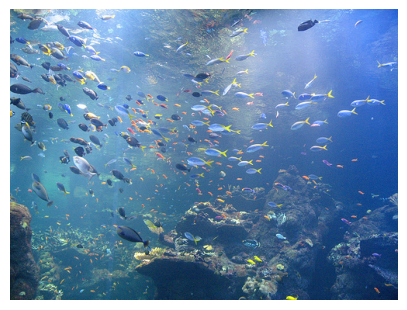

In [9]:
images = load_images(DATA_DIR, records)
example_record, example_image = next(images)
images.close()
print('Ảnh thử:', example_record)
plt.figure(figsize=(5, 5))
plt.imshow(example_image)
plt.axis('off')
plt.show()

## Bước 3 — Chọn đặc trưng cần khảo sát

| Giai đoạn tương đối | ResNet-50 V2 | ViT-B/16 V1 |
|---|---|---|
| 1 | layer1 | block 3 |
| 2 | layer2 | block 6 |
| 3 | layer3 | block 9 |
| 4 | layer4 | block 12 |

Đây là các mốc theo độ sâu, **không phải** các tầng tương đương về tính toán.
Với ResNet, lấy vector kênh ở giữa feature map, sau toàn bộ stage.
Với ViT, lấy vector của patch token ở gần tâm, sau toàn bộ block và trước
LayerNorm cuối của encoder. CLS vẫn tham gia attention nhưng không được chọn làm đầu ra.

Quy ước chỉ số bắt đầu từ 0: `row=H//2`, `col=W//2`.
Với lưới patch 14×14: chọn (7,7), token thứ `1 + 7*14 + 7 = 106` trong chuỗi có CLS.
Lưới chẵn không có duy nhất một ô tâm; vị trí receptive center giữa hai kiến trúc
cũng không trùng hoàn toàn. Notebook lưu vị trí cụ thể trong CSV.

Mỗi vector có nhiều số, cần chọn **một scalar** để backward.
Ta dùng $z=\frac{1}{C}\sum_k f_k^2$ (năng lượng trung bình của vector),
cùng quy tắc cho cả hai model. Đây là một lựa chọn thực nghiệm có chủ đích;
kết quả phụ thuộc lựa chọn scalar và không phải chuẩn toàn bộ Jacobian.
Không dùng trung bình kênh sau LayerNorm vì có thể gần hằng số và triệt tiêu gradient.

## Bước 4 — Từ gradient thành bản đồ ERF

Với $u$ là RGB trong [0,1] **sau resize/crop**, ta đo:

$$ E_{ij}=\sum_{c=1}^3\left|\frac{\partial z}{\partial u_{cij}}\right|,
   \qquad P_{ij}=E_{ij}/\sum_{ab}E_{ab}. $$

`requires_grad_(True)` yêu cầu PyTorch theo dõi ảnh đầu vào;
`autograd.grad(z, x)` tính độ nhạy của scalar với từng pixel.
`eval()` tắt dropout và dùng BatchNorm đã học, vẫn cho phép gradient.
Không bọc ERF trong `inference_mode()`.

Model nhận $x_c=(u_c-\mu_c)/\sigma_c$, nên phải chia gradient theo $x_c$
cho $\sigma_c$ để đổi về gradient theo RGB. Ta không tính đạo hàm ngược
qua phép resize/crop về ảnh gốc. Gradient thô được lưu riêng; bản đồ chuẩn hóa
mô tả phân bố tương đối. Tổng gradient thô không dùng để xếp hạng hai kiến trúc.

Đây là phép đo độ nhạy cục bộ của biểu diễn, không chứng minh pixel đó gây ra
quyết định phân loại. Cách scalar hóa và trị tuyệt đối là lựa chọn của notebook,
không phải sao chép nguyên xi mọi thiết lập của Luo et al. (2016).

In [10]:
def center_features(model, model_name, x):
    """Return center vectors AFTER each complete residual stage/block."""
    features = {}
    positions = {}
    if model_name == "resnet50":
        h = model.maxpool(model.relu(model.bn1(model.conv1(x))))
        for name in LAYERS[model_name]:
            h = getattr(model, name)(h)
            row, col = h.shape[-2] // 2, h.shape[-1] // 2
            features[name] = h[0, :, row, col]
            positions[name] = {"grid_row": row, "grid_col": col,
                               "grid_height": h.shape[-2], "grid_width": h.shape[-1],
                               "token_index": -1}
    elif model_name == "vit_b_16":
        # Match torchvision's patch embedding -> CLS -> position -> encoder path.
        # Stop before encoder.ln: channel averaging after LayerNorm is degenerate.
        h = model._process_input(x)
        grid = model.image_size // model.patch_size
        row, col = grid // 2, grid // 2
        token_index = 1 + row * grid + col  # +1 skips the CLS token.
        h = torch.cat([model.class_token.expand(x.shape[0], -1, -1), h], dim=1)
        h = model.encoder.dropout(h + model.encoder.pos_embedding)
        for depth, block in enumerate(model.encoder.layers, start=1):
            h = block(h)
            name = f"block{depth}"
            if name in LAYERS[model_name]:
                features[name] = h[0, token_index, :]
                positions[name] = {"grid_row": row, "grid_col": col,
                                   "grid_height": grid, "grid_width": grid,
                                   "token_index": token_index}
    else:
        raise ValueError(f"Unsupported model: {model_name}")
    return features, positions


@torch.enable_grad()
def compute_erf(model, model_name, normalized_image, std):
    """Differentiate center feature energy with respect to RGB crop in [0,1]."""
    if torch.is_inference_mode_enabled():
        raise RuntimeError("Run ERF outside torch.inference_mode().")
    if normalized_image.shape != (1, 3, 224, 224):
        raise ValueError("Expected one normalized RGB image: [1, 3, 224, 224].")
    if len(std) != 3 or any(value <= 0 for value in std):
        raise ValueError("Expected three positive RGB normalization std values.")
    model.eval()  # Disable dropout; use saved BatchNorm statistics.
    x = normalized_image.detach().clone().requires_grad_(True)
    features, positions = center_features(model, model_name, x)
    scale = x.new_tensor(std).view(1, 3, 1, 1)
    maps = {}
    for stage, (name, vector) in enumerate(features.items(), start=1):
        # One explicit scalar for both architectures. This is a sensitivity probe,
        # not an exact all-channel Jacobian norm or a class attribution.
        z = vector.square().mean()
        gradient = torch.autograd.grad(
            z, x, retain_graph=stage < len(features), create_graph=False,
        )[0]
        # x_norm=(RGB-mean)/std, so dz/dRGB = (dz/dx_norm)/std.
        raw = (gradient / scale).abs().sum(dim=1)[0].detach().cpu().numpy()
        raw = raw.astype(np.float32)
        if not np.isfinite(raw).all() or float(raw.sum()) <= 0:
            raise ValueError(f"Zero or non-finite gradient for {model_name}/{name}.")
        maps[name] = {"raw": raw, "stage": stage, "target_value": z.item(),
                      **positions[name]}
    return maps

## Bước 5 — Đo ERF bằng số, không chỉ nhìn màu

- **A50 / A90:** sắp pixel theo gradient giảm dần, lấy số pixel nhỏ nhất chứa
  ít nhất 50% / 90% tổng gradient rồi chia cho 224×224. Pixel có thể rời nhau;
  đây không phải bán kính, bounding box hay diện tích vùng liên thông.
- **Dispersion:** khoảng cách RMS tới trọng tâm phân bố gradient, dùng tọa độ
  x,y chuẩn hóa [0,1]. Cao hơn nghĩa là ảnh hưởng phân tán xa trọng tâm hơn.
- **Center / outer energy:** tỷ lệ gradient trong / ngoài hình vuông giữa ảnh,
  có cạnh bằng nửa chiều ảnh. Tâm ở đây là tâm ảnh, không phải vị trí feature.

Ví dụ minh họa: gradient đều trên toàn ảnh → A90 gần 90%; gradient chỉ tại
một pixel → A90 bằng 1/(224×224). Không suy ra model nào tốt hơn từ A90.

In [11]:
def erf_metrics(raw):
    """Area = smallest NUMBER of pixels reaching a fraction of absolute gradient."""
    raw = np.asarray(raw, dtype=np.float64)
    if raw.ndim != 2 or not np.isfinite(raw).all() or (raw < 0).any() or raw.sum() <= 0:
        raise ValueError("ERF must be a finite, nonnegative 2D map with positive sum.")
    p = raw / raw.sum()
    ranked = np.sort(p.ravel())[::-1]
    cumulative = np.cumsum(ranked)

    def area(q):
        count = min(np.searchsorted(cumulative, q, side="left") + 1, p.size)
        return float(count / p.size)

    yy, xx = np.indices(p.shape, dtype=np.float64)
    yy /= max(p.shape[0] - 1, 1)
    xx /= max(p.shape[1] - 1, 1)
    cy, cx = (p * yy).sum(), (p * xx).sum()
    dispersion = np.sqrt((p * ((yy - cy) ** 2 + (xx - cx) ** 2)).sum())
    # Central square occupies the middle half along each axis (~25% area).
    center = (np.abs(yy - 0.5) <= 0.25) & (np.abs(xx - 0.5) <= 0.25)
    center_energy = p[center].sum()
    return {
        "area50_fraction": area(0.5), "area90_fraction": area(0.9),
        "dispersion_normalized": float(dispersion),
        "center_energy_fraction": float(center_energy),
        "outer_energy_fraction": float(1 - center_energy),
        "centroid_y": float(cy), "centroid_x": float(cx),
        "raw_gradient_sum": float(raw.sum()),
    }

In [12]:
# Chỉ kiểm tra định nghĩa metric bằng mảng giả, không phải kết quả ImageNet.
uniform = np.ones((10, 10))
point = np.zeros((10, 10))
point[5, 5] = 1
print('Đều trên 100 pixel → A90:', erf_metrics(uniform)['area90_fraction'])
print('Tập trung 1/100 pixel → A90:', erf_metrics(point)['area90_fraction'])

Đều trên 100 pixel → A90: 0.9
Tập trung 1/100 pixel → A90: 0.01


In [13]:
def plot_image_maps(image_id, previews, destination=None):
    """Show each model's own crop and four ERF maps; color is log10 probability."""
    fig, axes = plt.subplots(2, 5, figsize=(16, 6), constrained_layout=True)
    for row, model_name in enumerate(LAYERS):
        crop, maps = previews[model_name]
        axes[row, 0].imshow(crop)
        axes[row, 0].set_title(f"{model_name}: RGB crop")
        for col, (layer, result) in enumerate(maps.items(), start=1):
            raw = result["raw"]
            probability = raw / raw.sum()
            heat = axes[row, col].imshow(
                np.log10(probability + 1e-12), cmap="magma", vmin=-8, vmax=-2,
                interpolation="nearest",
            )
            area90 = erf_metrics(raw)["area90_fraction"]
            axes[row, col].set_title(f"{layer}\nA90 = {area90:.1%}")
        for axis in axes[row]:
            axis.axis("off")
    fig.colorbar(heat, ax=axes[:, 1:].ravel().tolist(), shrink=0.7,
                 label="log10(normalized absolute gradient + 1e-12)")
    fig.suptitle(image_id)
    if destination is not None:
        fig.savefig(destination, dpi=160)
    return fig


def plot_summary(metrics, destination=None):
    """Error bars are across-image standard deviations, not confidence intervals."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    for model_name, group in metrics.groupby("model", sort=False):
        grouped = group.groupby("stage")
        for axis, metric, title in zip(
            axes, ["area90_fraction", "dispersion_normalized"],
            ["Smallest pixel area containing 90% gradient mass", "Spatial dispersion"],
        ):
            mean = grouped[metric].mean()
            sd = grouped[metric].std().fillna(0)
            axis.errorbar(mean.index, mean, yerr=sd, marker="o", capsize=3,
                          label=model_name)
            axis.set(title=title, xlabel="Relative stage (not equivalent layers)",
                     xticks=[1, 2, 3, 4])
            axis.grid(alpha=0.2)
            axis.legend()
    axes[0].set_ylabel("Fraction of input pixels (mean ± SD)")
    axes[1].set_ylabel("Normalized-coordinate RMS distance (mean ± SD)")
    if destination is not None:
        fig.savefig(destination, dpi=160)
    return fig

## Bước 6 — Định nghĩa runner và chạy một ảnh nếu cần kiểm tra lại

Ô helper dưới dùng `src.models.load_model` để nhận model, official transform và metadata.
`eval()` vẫn cho phép gradient. Đóng băng trọng số không ngăn gradient theo đầu vào.
Không đi qua `src.evaluation.evaluate`, `inference_mode` hoặc `no_grad` để tính ERF.

Trong `official`, ResNet dùng resize 232 và ViT 256, cùng center crop 224.
Trong `shared_vit_crop`, dùng chính official transform do loader trả về cho ViT cho cả hai model.
Đây là thí nghiệm nhạy với preprocessing riêng, không thay cấu hình baseline chính.

Kết quả mới dùng run ID duy nhất: CSV/JSON trong `results/metrics/experiments/erf/<run_id>/final/`,
figures trong `results/figures/experiments/erf/<run_id>/final/`.
Raw maps preview và checkpoint CSV nằm trong `intermediate/`, không đưa vào `final/`.

In [14]:
def run_experiment(records, data_dir, output_dir, device, seed=42,
                   preprocessing="official", num_previews=3, *, project_root,
                   allow_download=False, save_raw_maps=False, checkpoint_every=50):
    """Use shared model/data APIs; save ERF CSV/JSON and figures under final/."""
    if preprocessing not in {"official", "shared_vit_crop"}:
        raise ValueError("preprocessing must be official or shared_vit_crop.")
    if torch.is_inference_mode_enabled():
        raise RuntimeError("Run ERF outside torch.inference_mode().")
    records = list(records)
    if not records or len({r["image_id"] for r in records}) != len(records):
        raise ValueError("Provide a nonempty cohort with unique IDs.")
    if not isinstance(num_previews, int) or not 0 <= num_previews <= len(records):
        raise ValueError("num_previews must be between zero and the cohort size.")
    if type(checkpoint_every) is not int or checkpoint_every < 1:
        raise ValueError("checkpoint_every must be a positive integer.")
    if len(records) == 2000:
        validate_selected_cohort(records)
    root, output = Path(project_root), Path(output_dir)
    expected, figure_dir, intermediate = erf_output_paths(root, output.parent.name)
    if output.resolve() != expected.resolve():
        raise ValueError(f"Use the protocol metrics directory: {expected}")
    # A lightweight probe; the main loops below always exhaust the shared iterator.
    loader = load_images(data_dir, records[:1])
    try:
        next(loader)
    finally:
        loader.close()
    if output.exists() or figure_dir.exists() or intermediate.exists():
        raise FileExistsError("Run ID already exists; choose a new run_id.")
    output.mkdir(parents=True, exist_ok=False)
    figure_dir.mkdir(parents=True, exist_ok=False)
    intermediate.mkdir(parents=True, exist_ok=False)
    maps_dir = intermediate / "maps"
    maps_dir.mkdir()
    pd.DataFrame(records).to_csv(output / "selected_images.csv", index=False)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    config = json.loads((root / "configs/analysis_set.json").read_text("utf-8"))
    manifest = root / config["manifest"]
    preview_ids = {row["image_id"] for row in random.Random(seed).sample(records, num_previews)}
    metadata = {
        "experiment": "erf", "run_id": output.parent.name,
        "status": "running", "num_images": len(records), "seed": seed,
        "device": str(device), "torch": torch.__version__,
        "torchvision": torchvision.__version__, "numpy": np.__version__, "pandas": pd.__version__,
        "preprocessing": preprocessing, "condition": preprocessing, "severity": "",
        "batch_size": 1, "allow_download": allow_download, "checkpoint_every": checkpoint_every,
        "target": "mean(square(center_feature_vector)); post-stage/post-block, pre-final-LN",
        "center_rule": "row=grid_height//2, col=grid_width//2; zero-based",
        "gradient_coordinates": "RGB [0,1] AFTER resize/crop, BEFORE normalization",
        "layers": LAYERS, "models": {}, "exclusions": [],
        "selection_rule": "random.Random(seed); labels ascending 0..999; sample 2 from each ID-sorted class of the shared manifest; no correctness filtering",
        "cohort_kind": "class_balanced_2000_subset" if len(records) == 2000 else "smoke_subset",
        "num_classes": len({r["label"] for r in records}),
        "images_per_class": 2 if len(records) == 2000 else None,
        "manifest": str(manifest),
        "manifest_sha256": hashlib.sha256(manifest.read_bytes().replace(b"\r\n", b"\n")).hexdigest(),
        "selected_images_sha256": hashlib.sha256((output / "selected_images.csv").read_bytes()).hexdigest(),
        "cohort_sha256_lf": hashlib.sha256((output / "selected_images.csv").read_bytes().replace(b"\r\n", b"\n")).hexdigest(),
        "preview_ids": sorted(preview_ids), "raw_maps": "all" if save_raw_maps else "previews_only",
        "metrics_dir": str(output), "figures_dir": str(figure_dir),
        "code": erf_code_provenance(root),
        "metric_units": {"area50_fraction": "fraction of input pixels", "area90_fraction": "fraction of input pixels",
                         "dispersion_normalized": "normalized-coordinate RMS distance"},
    }
    metadata_path = output / "metadata.json"
    def save_metadata():
        metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    save_metadata()
    rows, previews, model, vit_transform = [], {}, None, None
    try:
        # ViT first provides its official transform for the common-view sensitivity run.
        for model_name in ("vit_b_16", "resnet50"):
            model, official_transform, model_metadata = load_model(
                model_name, device=device, allow_download=allow_download,
            )
            if model_name == "vit_b_16":
                vit_transform = official_transform
            transform = vit_transform if preprocessing == "shared_vit_crop" else official_transform
            metadata["models"][model_name] = {
                "weights": model_metadata["weights"], "transform": repr(transform),
                "baseline_loader": model_metadata,
            }
            save_metadata()
            model.requires_grad_(False)  # Input gradients remain enabled; no training.
            for image_number, (record, image) in enumerate(
                tqdm(load_images(data_dir, records), total=len(records), desc=model_name), start=1
            ):
                x = transform(image).unsqueeze(0).to(device)
                maps = compute_erf(model, model_name, x, transform.std)
                image_id = record["image_id"]
                if save_raw_maps or image_id in preview_ids:
                    np.savez_compressed(maps_dir / f"{model_name}_{record['dataset_index']:05d}.npz",
                                        **{name: result["raw"] for name, result in maps.items()})
                for layer, result in maps.items():
                    rows.append({**record, "model": model_name, "model_name": model_name,
                                 "experiment": "erf", "run_id": output.parent.name,
                                 "condition": preprocessing, "severity": "", "layer": layer,
                                 **{k: v for k, v in result.items() if k != "raw"},
                                 **erf_metrics(result["raw"])})
                if image_id in preview_ids:
                    rgb = (x[0].detach().cpu() * torch.tensor(transform.std)[:, None, None]
                           + torch.tensor(transform.mean)[:, None, None])
                    previews.setdefault(image_id, {})[model_name] = (
                        rgb.permute(1, 2, 0).clamp(0, 1).numpy(), maps)
                # Save first image and every K images; limit Drive CSV rewrites.
                if image_number == 1 or image_number % checkpoint_every == 0:
                    pd.DataFrame(rows).to_csv(intermediate / "metrics_checkpoint.csv", index=False)
                del x, maps
            # Flush the model's last image even if N is not divisible by K.
            pd.DataFrame(rows).to_csv(intermediate / "metrics_checkpoint.csv", index=False)
            del model
            model = None
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        metrics = pd.DataFrame(rows)
        if len(metrics) != len(records) * 8 or metrics.duplicated(["image_id", "model", "stage"]).any():
            raise ValueError("Expected 8 unique image/model/stage rows per selected image.")
        metrics.to_csv(output / "metrics.csv", index=False)
        summary = metrics.groupby(["model", "stage", "layer"])[[
            "area50_fraction", "area90_fraction", "dispersion_normalized",
            "center_energy_fraction", "outer_energy_fraction",
        ]].agg(["mean", "std", "count"])
        summary.to_csv(output / "summary.csv")
        caption = f"{preprocessing}; ResNet50 V2 / ViT-B16 V1; target: center-feature mean-square energy"
        for index, (image_id, preview) in enumerate(previews.items()):
            fig = plot_image_maps(image_id, preview)
            fig.suptitle(f"{image_id}\n{caption}", fontsize=10)
            fig.savefig(figure_dir / f"image_{index:02d}.png", dpi=160)
            plt.close(fig)
        fig = plot_summary(metrics)
        fig.suptitle(caption, fontsize=9)
        fig.savefig(figure_dir / "comparison.png", dpi=160)
        plt.close(fig)
        metadata["status"] = "complete"
        save_metadata()
        return metrics, summary, previews
    except Exception as error:
        metadata.update(status="failed", error=str(error))
        save_metadata()
        raise
    finally:
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 171MB/s]


vit_b_16:   0%|          | 0/1 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 187MB/s]


resnet50:   0%|          | 0/1 [00:00<?, ?it/s]

,model,layer,grid_row,grid_col,token_index,area50_fraction,area90_fraction,dispersion_normalized
0,vit_b_16,block3,7,7,106,0.051000,0.540099,0.312352
1,vit_b_16,block6,7,7,106,0.135364,0.606126,0.368710
2,vit_b_16,block9,7,7,106,0.152702,0.625678,0.389067
3,vit_b_16,block12,7,7,106,0.134367,0.613939,0.365983
4,resnet50,layer1,28,28,-1,0.001415,0.005959,0.029998
5,resnet50,layer2,14,14,-1,0.005361,0.030054,0.065130
6,resnet50,layer3,7,7,-1,0.055345,0.325016,0.213663
7,resnet50,layer4,3,3,-1,0.157366,0.583586,0.330413


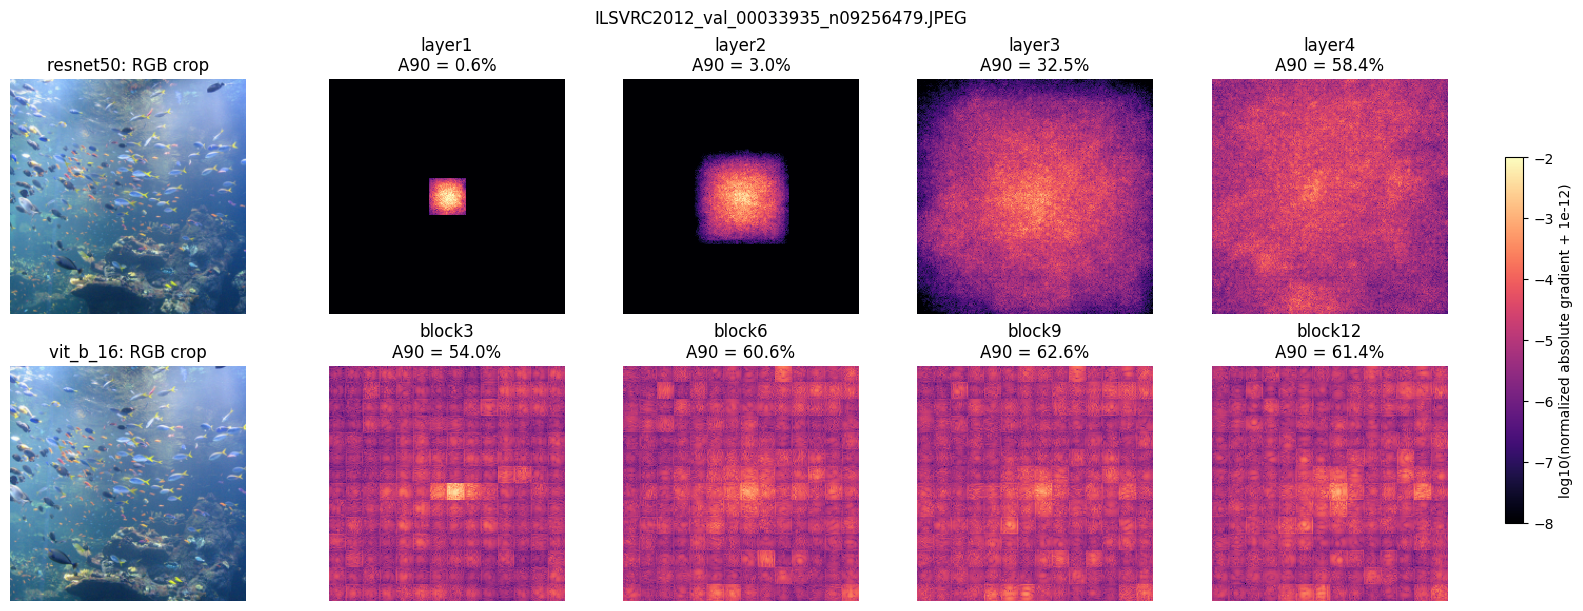

Metrics: /content/drive/MyDrive/cnn-vit-interpretability/results/metrics/experiments/erf/smoke_1_official_20261103T160628_906449Z/final
Figures: /content/drive/MyDrive/cnn-vit-interpretability/results/figures/experiments/erf/smoke_1_official_20261103T160628_906449Z/final


In [15]:
from datetime import datetime, timezone

def new_run_dir(name, preprocessing='official'):
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    return erf_output_paths(PROJECT_ROOT, f'{name}_{preprocessing}_{stamp}')[0]

smoke_dir = new_run_dir('smoke_1')
smoke_metrics, smoke_summary, smoke_previews = run_experiment(
    records[:1], DATA_DIR, smoke_dir, DEVICE,
    seed=SEED, preprocessing='official', num_previews=1,
    project_root=PROJECT_ROOT, allow_download=ALLOW_DOWNLOAD,
    save_raw_maps=SAVE_RAW_MAPS, checkpoint_every=CHECKPOINT_EVERY,
)
display(smoke_metrics[['model', 'layer', 'grid_row', 'grid_col', 'token_index',
                       'area50_fraction', 'area90_fraction', 'dispersion_normalized']])
fig = plot_image_maps(records[0]['image_id'], smoke_previews[records[0]['image_id']])
plt.show()
print('Metrics:', smoke_dir)
print('Figures:', erf_output_paths(PROJECT_ROOT, smoke_dir.parent.name)[1])

**Trước khi chạy nhiều ảnh:** xác nhận có 8 dòng metrics (2 model × 4 tầng),
gradient hữu hạn và tổng dương, A50 ≤ A90 ≤ 1. Nếu lỗi thiếu shard, quay lại
bước 1. Nếu GPU hết bộ nhớ, khởi động lại runtime để giải phóng model còn sót
từ các lần chạy trước; notebook đã dùng từng ảnh và từng model.

Không kết luận xu hướng từ một ảnh. Ta chuyển sang nhiều ảnh để tính phân bố.

In [16]:
assert len(smoke_metrics) == 8
assert np.isfinite(smoke_metrics['raw_gradient_sum']).all()
assert (smoke_metrics['raw_gradient_sum'] > 0).all()
assert (smoke_metrics['area50_fraction'] <= smoke_metrics['area90_fraction']).all()
assert smoke_metrics['area90_fraction'].between(0, 1).all()
print('Kiểm tra một ảnh đạt. Có thể chuyển sang tập nhỏ.')

Kiểm tra một ảnh đạt. Có thể chuyển sang tập nhỏ.


## Bước 7 — Official trên 2.000 ảnh

OFFICIAL_RUN_DIR = None để chạy mới. Có official 2.000 ảnh complete thì điền đường dẫn
.../final/ để nạp lại. Run 100 ảnh không hợp lệ cho cohort này.
Mỗi lượt có **16.000 dòng = 2.000 ảnh × 2 model × 4 tầng**.

Checkpoint ghi mỗi 50 ảnh vào intermediate/. Chỉ nạp lại run complete; chưa có resume
lượt bị ngắt. Thanh sai số summary là SD giữa ảnh, không phải CI.

vit_b_16:   0%|          | 0/2000 [00:00<?, ?it/s]

resnet50:   0%|          | 0/2000 [00:00<?, ?it/s]

area50_fraction                 area90_fraction  \
                                  mean       std count            mean   
model    stage layer                                                     
resnet50 1     layer1         0.001513  0.000220  2000        0.006474   
         2     layer2         0.006306  0.001170  2000        0.029438   
         3     layer3         0.043193  0.012148  2000        0.237820   
         4     layer4         0.132744  0.025833  2000        0.529301   
vit_b_16 1     block3         0.022043  0.013129  2000        0.394165   
         2     block6         0.079557  0.030382  2000        0.490433   
         3     block9         0.110699  0.035904  2000        0.541637   
         4     block12        0.107031  0.032919  2000        0.535330   

                                       dispersion_normalized                  \
                             std count                  mean       std count   
model    stage layer                                                           
resnet50 1     layer1   0.000555  2000              0.030978  0.001504  2000   
         2     layer2   0.003642  2000              0.066050  0.004566  2000   
         3     layer3   0.047922  2000              0.186414  0.020116  2000   
         4     layer4   0.052110  2000              0.305299  0.023774  2000   
vit_b_16 1     block3   0.109802  2000              0.277642  0.031646  2000   
         2     block6   0.088893  2000              0.310707  0.033528  2000   
         3     block9   0.080414  2000              0.339820  0.036270  2000   
         4     block12  0.075254  2000              0.351371  0.038426  2000   

                       center_energy_fraction                      \
                                         mean           std count   
model    stage layer                                                
resnet50 1     layer1                1.000000  5.695039e-17  2000   
         2     layer2                1.000000  9.217825e-17  2000   
         3     layer3                0.859943  4.976869e-02  2000   
         4     layer4                0.519009  8.190041e-02  2000   
vit_b_16 1     block3                0.649559  7.248328e-02  2000   
         2     block6                0.563163  8.817673e-02  2000   
         3     block9                0.478662  1.005875e-01  2000   
         4     block12               0.438345  1.122733e-01  2000   

                       outer_energy_fraction                      
                                        mean           std count  
model    stage layer                                              
resnet50 1     layer1           1.049161e-17  5.603021e-17  2000  
         2     layer2           1.487699e-17  9.096919e-17  2000  
         3     layer3           1.400566e-01  4.976869e-02  2000  
         4     layer4           4.809910e-01  8.190041e-02  2000  
vit_b_16 1     block3           3.504406e-01  7.248328e-02  2000  
         2     block6           4.368366e-01  8.817673e-02  2000  
         3     block9           5.213376e-01  1.005875e-01  2000  
         4     block12          5.616547e-01  1.122733e-01  2000

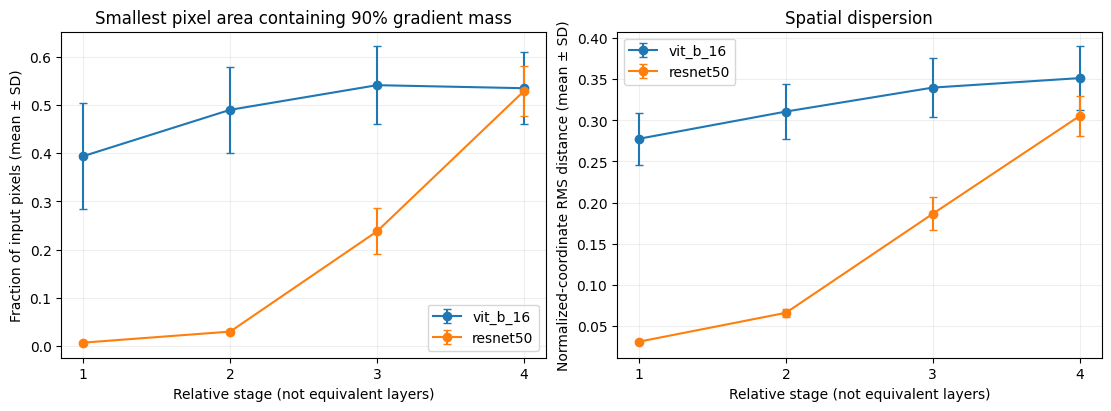

Official hoàn tất: /content/drive/MyDrive/cnn-vit-interpretability/results/metrics/experiments/erf/main_2000_official_20261103T160959_331099Z/final
Figures: /content/drive/MyDrive/cnn-vit-interpretability/results/figures/experiments/erf/main_2000_official_20261103T160959_331099Z/final
Số dòng metrics: 16000 | Mong đợi: 16000


In [17]:
from datetime import datetime, timezone

# None: chạy mới. Hoặc Path('/content/drive/.../main_2000_official_.../final') để nạp lại.
OFFICIAL_RUN_DIR = None
validate_selected_cohort(records)
if OFFICIAL_RUN_DIR is None:
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    run_dir = erf_output_paths(PROJECT_ROOT, f'main_{NUM_IMAGES}_official_{stamp}')[0]
    metrics, summary, previews = run_experiment(
        records, DATA_DIR, run_dir, DEVICE,
        seed=SEED, preprocessing='official', num_previews=3,
        project_root=PROJECT_ROOT, allow_download=ALLOW_DOWNLOAD,
        save_raw_maps=SAVE_RAW_MAPS, checkpoint_every=CHECKPOINT_EVERY,
    )
else:
    run_dir = Path(OFFICIAL_RUN_DIR)
    metrics, _ = load_completed_erf_run(run_dir, records, 'official', SEED)
    summary = metrics.groupby(['model', 'stage', 'layer'])[
        ['area50_fraction', 'area90_fraction', 'dispersion_normalized',
         'center_energy_fraction', 'outer_energy_fraction']
    ].agg(['mean', 'std', 'count'])
display(summary)
fig = plot_summary(metrics)
plt.show()
print('Official hoàn tất:', run_dir)
print('Figures:', erf_output_paths(PROJECT_ROOT, run_dir.parent.name)[1])
print('Số dòng metrics:', len(metrics), '| Mong đợi:', 8 * NUM_IMAGES)

## Bước 8 — Đọc và viết kết quả

Bảng dưới so sánh trên **cùng từng ảnh**, với chênh lệch A90 = ViT − ResNet.
Giá trị dương nghĩa là ViT cần nhiều pixel hơn để chứa 90% gradient theo phép đo này.
Chỉ ghép theo giai đoạn tương đối; không khẳng định layer1 tương đương block3.

In [18]:
paired = metrics.pivot(index=['image_id', 'stage'], columns='model', values='area90_fraction')
paired['vit_minus_resnet_pp'] = 100 * (paired['vit_b_16'] - paired['resnet50'])
paired_summary = paired.groupby('stage')['vit_minus_resnet_pp'].agg(['mean', 'std', 'count'])
paired_summary.to_csv(run_dir / 'paired_area90_difference.csv')
display(paired_summary)

,mean,std,count
stage,,,
1,38.769053,10.979504,2000
2,46.099506,8.816807,2000
3,30.381682,7.145436,2000
4,0.602888,7.482199,2000


## Bước 8a — Xác minh official và phương pháp thống kê

Nạp CSV từ đĩa; chỉ nhận run complete trên chính cohort 2.000 ảnh, 1.000 lớp, 2 ảnh/lớp,
seed 42. Không coi 16.000 dòng metrics là 16.000 quan sát độc lập: mỗi phép so sánh
model/stage/metric/condition có **2.000 cặp ảnh**.

- Hiệu số ViT − ResNet; A90 dùng điểm phần trăm, dispersion giữ đơn vị RMS chuẩn hóa.
- Wilcoxon signed-rank hai phía dùng hiệu số làm tròn 12 chữ số, bỏ hiệu số 0.
  Tất cả bằng 0 thì p = 1. Diễn giải vị trí cần giả định đối xứng; không kiểm định trực tiếp trung bình.
- Bootstrap ghép cặp theo ảnh: lấy mẫu lại 2.000 hiệu số 20.000 lần, seed cố định,
  lấy CI percentile 95% của trung bình. Không bootstrap hai model tách riêng.
  Resample theo ảnh từ cohort cân bằng quan sát, không giữ quota 2 ảnh/lớp trong mỗi lần;
  CI là xấp xỉ cho trung bình theo phân bố ảnh này, không phải CI riêng từng lớp.
- Holm hiệu chỉnh chung 16 p-value (2 crop × 2 metric × 4 stage), ngưỡng 0,05.
  CI riêng từng so sánh chưa hiệu chỉnh đa kiểm định; đọc p_holm khi kết luận kiểm định.
- Không bỏ cặp thiếu/NaN, không đổi subset/cỡ mẫu dựa vào kết quả.

Các hàm thống kê đã được định nghĩa trực tiếp ở phần đầu notebook.

In [19]:
validate_selected_cohort(records)
if NUM_IMAGES != 2000 or SEED != 42:
    raise ValueError('Giữ NUM_IMAGES = 2000 và SEED = 42 cho thiết kế đã chốt.')
if 'run_dir' not in globals():
    raise RuntimeError('Chạy Bước 7 trước để tạo hoặc nạp official 2.000 ảnh.')
official_run_dir = Path(run_dir)
official_metrics, official_metadata = load_completed_erf_run(
    official_run_dir, records, 'official', SEED,
)
print('Official hợp lệ:', official_run_dir)
print('Số ảnh:', official_metrics.image_id.nunique(), '| Số dòng:', len(official_metrics))
print('SciPy:', scipy.__version__)

Official hợp lệ: /content/drive/MyDrive/cnn-vit-interpretability/results/metrics/experiments/erf/main_2000_official_20261103T160959_331099Z/final
Số ảnh: 2000 | Số dòng: 16000
SciPy: 1.16.3


## Bước 8b — Shared crop trên cùng 2.000 ảnh

Cả hai model dùng official transform do loader trả cho ViT: resize 256, crop 224,
cùng mean/std. Trọng số, target, tầng, seed và cohort giữ nguyên.
Báo cáo riêng vì preprocessing của ResNet đã thay đổi so với official.

Mặc định chạy mới; có run 2.000 ảnh complete thì điền SHARED_RUN_DIR để nạp lại.
Không đổi records hoặc nạp run 100 ảnh. Không ghi đè kết quả cũ.

vit_b_16:   0%|          | 0/2000 [00:00<?, ?it/s]

resnet50:   0%|          | 0/2000 [00:00<?, ?it/s]

Shared crop hợp lệ: /content/drive/MyDrive/cnn-vit-interpretability/results/metrics/experiments/erf/main_2000_shared_vit_crop_20261103T161602_476613Z/final
Số ảnh: 2000 | Số dòng: 16000


area90_fraction                 dispersion_normalized  \
                                  mean       std count                  mean   
model    stage layer                                                           
resnet50 1     layer1         0.006474  0.000568  2000              0.030983   
         2     layer2         0.029540  0.003677  2000              0.066133   
         3     layer3         0.241849  0.046929  2000              0.188045   
         4     layer4         0.533977  0.051420  2000              0.306806   
vit_b_16 1     block3         0.394165  0.109802  2000              0.277642   
         2     block6         0.490433  0.088893  2000              0.310707   
         3     block9         0.541637  0.080414  2000              0.339820   
         4     block12        0.535330  0.075254  2000              0.351371   

                                        
                             std count  
model    stage layer                    
resnet50 1     layer1   0.001511  2000  
         2     layer2   0.004578  2000  
         3     layer3   0.019600  2000  
         4     layer4   0.023454  2000  
vit_b_16 1     block3   0.031646  2000  
         2     block6   0.033528  2000  
         3     block9   0.036270  2000  
         4     block12  0.038426  2000

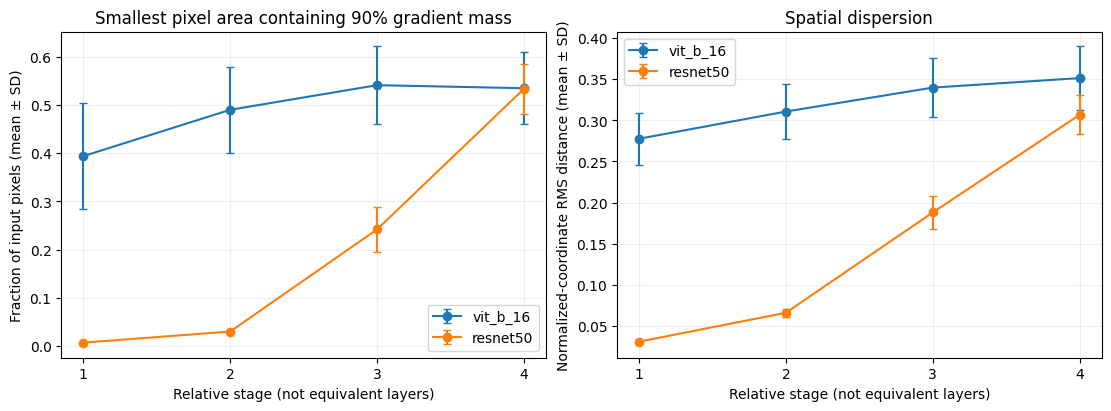

In [20]:
from datetime import datetime, timezone

# None: tạo lượt mới. Hoặc Path('/content/drive/.../main_2000_shared_vit_crop_.../final') để nạp lại.
SHARED_RUN_DIR = None
validate_selected_cohort(records)

if SHARED_RUN_DIR is None:
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    shared_run_dir = erf_output_paths(PROJECT_ROOT, f'main_2000_shared_vit_crop_{stamp}')[0]
    shared_metrics, shared_summary, shared_previews = run_experiment(
        records, DATA_DIR, shared_run_dir, DEVICE,
        seed=SEED, preprocessing='shared_vit_crop', num_previews=3,
        project_root=PROJECT_ROOT, allow_download=ALLOW_DOWNLOAD,
        save_raw_maps=SAVE_RAW_MAPS, checkpoint_every=CHECKPOINT_EVERY,
    )
else:
    shared_run_dir = Path(SHARED_RUN_DIR)

# Nạp lại từ đĩa: xác nhận chính các CSV đã lưu, không chỉ biến còn trong kernel.
shared_metrics, shared_metadata = load_completed_erf_run(
    shared_run_dir, records, 'shared_vit_crop', SEED,
)
validate_erf_run_pair(official_metadata, shared_metadata)
print('Shared crop hợp lệ:', shared_run_dir)
print('Số ảnh:', shared_metrics.image_id.nunique(), '| Số dòng:', len(shared_metrics))
display(shared_metrics.groupby(['model', 'stage', 'layer'])[
    ['area90_fraction', 'dispersion_normalized']
].agg(['mean', 'std', 'count']))
fig = plot_summary(shared_metrics)
plt.show()

## Bước 8c — Kiểm định, CI và độ nhạy với preprocessing

`paired_tests.csv` có 16 hàng. `mean_difference` và CI dùng đơn vị ở cột `unit`.
`reject_holm_0_05` dựa vào p-value đã hiệu chỉnh. Dấu dương nghĩa là ViT có metric lớn hơn;
không suy ra model tốt hơn, và không kết luận từ mỗi p-value.

`crop_sensitivity.csv` đo trên từng ảnh: **(ViT − ResNet)shared − (ViT − ResNet)official**.
CI ở bảng này chỉ mang tính mô tả, không thêm một họ kiểm định mới. Xem độ lớn,
dấu và độ bất định để đánh giá mức phụ thuộc preprocessing; CI chứa 0 không chứng minh
hai thiết lập tương đương. Chạy chung crop cũng không loại bỏ khác biệt huấn luyện/trọng số.

Các bảng/biểu đồ dưới chỉ có sau khi hai lượt thực sự hoàn tất. Số liệu tổng hợp
cũ không đủ để suy ra Wilcoxon hay bootstrap: cần CSV metric từng ảnh.

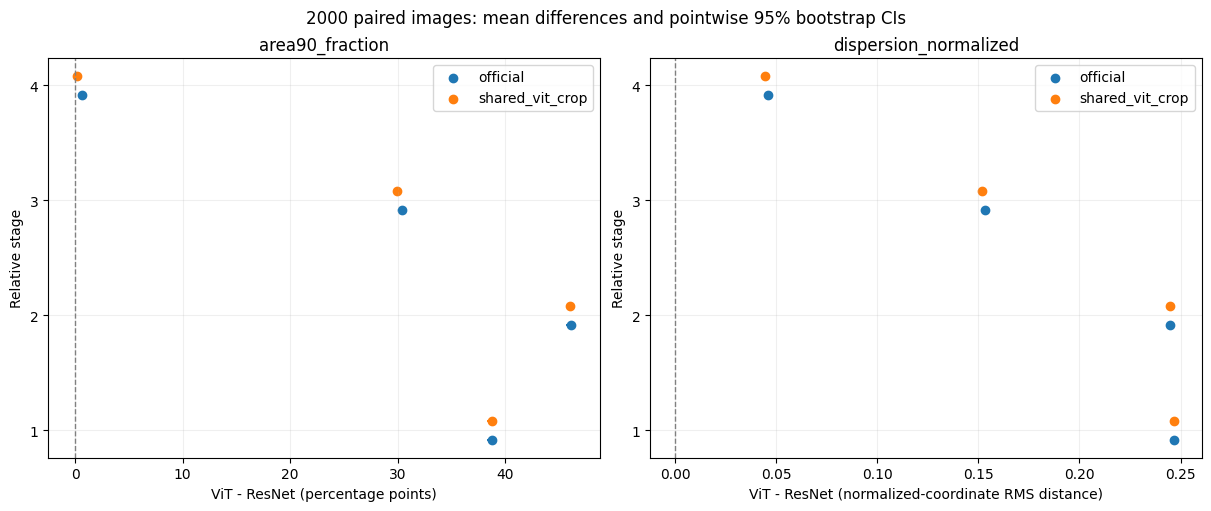

,preprocessing,metric,stage,resnet_layer,vit_layer,n_pairs,n_nonzero_wilcoxon,unit,resnet_mean,vit_mean,mean_difference,median_difference,sd_difference,mean_ci95_low,mean_ci95_high,wilcoxon_statistic,p_value,p_holm,reject_holm_0_05
0,official,area90_fraction,1,layer1,block3,2000,2000,percentage points,0.647407,39.416460,38.769053,40.438656,10.979504,38.286444,39.248135,0.0,0.000000e+00,0.000000e+00,True
1,official,area90_fraction,2,layer2,block6,2000,2000,percentage points,2.943816,49.043322,46.099506,48.015984,8.816807,45.710962,46.488599,0.0,0.000000e+00,0.000000e+00,True
2,official,area90_fraction,3,layer3,block9,2000,2000,percentage points,23.781972,54.163655,30.381682,31.555923,7.145436,30.066785,30.696831,44.0,0.000000e+00,0.000000e+00,True
3,official,area90_fraction,4,layer4,block12,2000,1999,percentage points,52.930118,53.533006,0.602888,1.320352,7.482199,0.276754,0.926814,815045.5,8.897151e-13,1.779430e-12,True
4,official,dispersion_normalized,1,layer1,block3,2000,2000,normalized-coordinate RMS distance,0.030978,0.277642,0.246663,0.250769,0.031712,0.245263,0.248039,0.0,0.000000e+00,0.000000e+00,True
5,official,dispersion_normalized,2,layer2,block6,2000,2000,normalized-coordinate RMS distance,0.066050,0.310707,0.244657,0.245816,0.033434,0.243190,0.246127,0.0,0.000000e+00,0.000000e+00,True
6,official,dispersion_normalized,3,layer3,block9,2000,2000,normalized-coordinate RMS distance,0.186414,0.339820,0.153406,0.154813,0.030811,0.152063,0.154766,0.0,0.000000e+00,0.000000e+00,True
7,official,dispersion_normalized,4,layer4,block12,2000,2000,normalized-coordinate RMS distance,0.305299,0.351371,0.046072,0.047663,0.033703,0.044605,0.047559,67297.0,7.880379e-286,3.152152e-285,True
8,shared_vit_crop,area90_fraction,1,layer1,block3,2000,2000,percentage points,0.647377,39.416460,38.769083,40.384845,10.981078,38.291731,39.245358,0.0,0.000000e+00,0.000000e+00,True
9,shared_vit_crop,area90_fraction,2,layer2,block6,2000,2000,percentage points,2.953959,49.043322,46.089362,48.048868,8.833498,45.702627,46.468975,0.0,0.000000e+00,0.000000e+00,True


,metric,stage,unit,n_pairs,official_gap_mean,shared_gap_mean,gap_change_mean,mean_ci95_low,mean_ci95_high
0,area90_fraction,1,percentage points,2000,38.769053,38.769083,0.000030,-0.001710,0.001747
1,area90_fraction,2,percentage points,2000,46.099506,46.089362,-0.010143,-0.018566,-0.001708
2,area90_fraction,3,percentage points,2000,30.381682,29.978792,-0.402891,-0.491052,-0.314180
3,area90_fraction,4,percentage points,2000,0.602888,0.135284,-0.467604,-0.589697,-0.349058
4,dispersion_normalized,1,normalized-coordinate RMS distance,2000,0.246663,0.246658,-0.000005,-0.000054,0.000044
5,dispersion_normalized,2,normalized-coordinate RMS distance,2000,0.244657,0.244574,-0.000083,-0.000187,0.000023
6,dispersion_normalized,3,normalized-coordinate RMS distance,2000,0.153406,0.151774,-0.001632,-0.002002,-0.001255
7,dispersion_normalized,4,normalized-coordinate RMS distance,2000,0.046072,0.044565,-0.001507,-0.002089,-0.000919


CSV/JSON: /content/drive/MyDrive/cnn-vit-interpretability/results/metrics/experiments/erf/paired_2000_official_vs_shared_vit_crop_20261103T162207_281699Z/final
Figures: /content/drive/MyDrive/cnn-vit-interpretability/results/figures/experiments/erf/paired_2000_official_vs_shared_vit_crop_20261103T162207_281699Z/final


In [21]:
N_BOOTSTRAP = 20_000
validate_selected_cohort(records)
# Kiểm tra lại dữ liệu đầu vào trước khi phân tích.
validate_erf_run_pair(official_metadata, shared_metadata)
paired_differences = pd.concat([
    paired_erf_differences(official_metrics, records, 'official'),
    paired_erf_differences(shared_metrics, records, 'shared_vit_crop'),
], ignore_index=True)
paired_tests = paired_erf_tests(paired_differences, seed=SEED, n_resamples=N_BOOTSTRAP)
crop_sensitivity = erf_crop_sensitivity(paired_differences, seed=SEED, n_resamples=N_BOOTSTRAP)
assert len(paired_tests) == 16 and paired_tests.n_pairs.eq(NUM_IMAGES).all()
assert len(crop_sensitivity) == 8 and crop_sensitivity.n_pairs.eq(NUM_IMAGES).all()

stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
analysis_run_id = f'paired_{NUM_IMAGES}_official_vs_shared_vit_crop_{stamp}'
analysis_dir, analysis_figure_dir, _ = erf_output_paths(PROJECT_ROOT, analysis_run_id)
if analysis_dir.exists() or analysis_figure_dir.exists():
    raise FileExistsError('Run ID phân tích đã tồn tại.')
analysis_dir.mkdir(parents=True, exist_ok=False)
analysis_figure_dir.mkdir(parents=True, exist_ok=False)
pd.DataFrame(records).to_csv(analysis_dir / 'selected_images.csv', index=False)
# Lưu cohort metrics vào final mới; không di chuyển/ghi đè run official lịch sử.
for mode, frame in [('official', official_metrics), ('shared_vit_crop', shared_metrics)]:
    frame.assign(experiment='erf', condition=mode, model_name=frame['model']).to_csv(
        analysis_dir / f'{mode}_metrics.csv', index=False)
paired_differences.to_csv(analysis_dir / 'paired_differences.csv', index=False)
paired_tests.to_csv(analysis_dir / 'paired_tests.csv', index=False)
crop_sensitivity.to_csv(analysis_dir / 'crop_sensitivity.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for axis, (metric, (_, unit)) in zip(axes, ERF_METRICS.items()):
    for mode, offset, color in [('official', -0.08, 'tab:blue'),
                                 ('shared_vit_crop', 0.08, 'tab:orange')]:
        group = paired_tests[(paired_tests.metric == metric) &
                             (paired_tests.preprocessing == mode)].sort_values('stage')
        y = group.stage.to_numpy() + offset
        axis.hlines(y, group.mean_ci95_low, group.mean_ci95_high, color=color)
        axis.scatter(group.mean_difference, y, color=color, label=mode)
    axis.axvline(0, color='gray', linestyle='--', linewidth=1)
    axis.set(xlabel=f'ViT - ResNet ({unit})', ylabel='Relative stage',
             yticks=[1, 2, 3, 4], title=metric)
    axis.grid(alpha=0.2)
    axis.legend()
fig.suptitle(f'{NUM_IMAGES} paired images: mean differences and pointwise 95% bootstrap CIs')
fig.savefig(analysis_figure_dir / 'paired_mean_ci95.png', dpi=160)
plt.show()

provenance = {
    'experiment': 'erf', 'run_id': analysis_run_id, 'status': 'complete',
    'num_images': NUM_IMAGES, 'num_classes': NUM_CLASSES, 'images_per_class': IMAGES_PER_CLASS,
    'seed': SEED, 'bootstrap_resamples': N_BOOTSTRAP,
    'cohort_kind': 'class_balanced_2000_subset', 'selection_rule': official_metadata['selection_rule'],
    'exclusions': [], 'batch_size': 1, 'device': str(DEVICE),
    'sample_size_rationale': {'pilot_paired_sd_A90_pp': 11.127155,
        'target_pointwise_ci95_half_width_pp': 0.5, 'normal_approximation_n': 1903,
        'chosen_n': NUM_IMAGES, 'reason': 'planning precision; 2 images for each of 1000 classes',
        'limitation': 'planning estimate, not a guaranteed CI or Wilcoxon power'},
    'manifest': str(PROJECT_ROOT / 'data/manifests/analysis_10000_seed42.csv'),
    'manifest_sha256': hashlib.sha256((PROJECT_ROOT / 'data/manifests/analysis_10000_seed42.csv')
        .read_bytes().replace(b'\r\n', b'\n')).hexdigest(),
    'cohort_sha256_lf': hashlib.sha256((analysis_dir / 'selected_images.csv')
        .read_bytes().replace(b'\r\n', b'\n')).hexdigest(),
    'code': erf_code_provenance(PROJECT_ROOT),
    'models': {'official': official_metadata['models'], 'shared_vit_crop': shared_metadata['models']},
    'target': official_metadata['target'], 'layers': official_metadata['layers'],
    'gradient_coordinates': official_metadata['gradient_coordinates'],
    'metrics_dir': str(analysis_dir), 'figures_dir': str(analysis_figure_dir),
    'ci': 'paired-image percentile bootstrap; pointwise 95%; not multiplicity-adjusted',
    'ci_resampling_unit': 'image pair; class quotas not fixed within resamples',
    'test': 'two-sided Wilcoxon signed-rank, zero_method=wilcox, method=auto',
    'wilcoxon_difference_round_decimals': 12,
    'multiplicity': 'Holm over all 16 model comparisons; alpha=0.05',
    'crop_sensitivity': 'descriptive paired gap changes, pointwise bootstrap CIs',
    'versions': {'numpy': np.__version__, 'pandas': pd.__version__, 'scipy': scipy.__version__,
                 'torch': torch.__version__, 'torchvision': torchvision.__version__},
    'runs': {mode: {'path': str(directory), 'metrics_sha256': hashlib.sha256(
        (directory / 'metrics.csv').read_bytes()).hexdigest(),
        'selected_images_sha256': metadata['selected_images_sha256']}
        for mode, directory, metadata in [
            ('official', official_run_dir, official_metadata),
            ('shared_vit_crop', shared_run_dir, shared_metadata)]},
}
(analysis_dir / 'metadata.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
display(paired_tests)
display(crop_sensitivity)
print('CSV/JSON:', analysis_dir)
print('Figures:', analysis_figure_dir)

## Viết báo cáo sau khi có số liệu thật

**Methodology:** 2.000 ảnh, 2 ảnh/lớp, seed 42, từ manifest đã chốt; trích lý do cỡ mẫu
ở đầu notebook. Mô tả shared loaders, đúng checkpoint, target/scalar, tọa độ gradient,
các stage tương đối, hai điều kiện crop và phương pháp thống kê.

**Results:** điền sau khi cả hai run complete. Trích mean_difference, CI95%, p_holm,
đơn vị và n = 2.000 từ paired_tests.csv; báo cáo cả kết quả không có ý nghĩa.
Mốc ±0,5 điểm phần trăm là mục tiêu lập kế hoạch, không tự điền thay CI thực tế.
Không sao chép số liệu 100 ảnh vào Results của lượt này.

**Discussion:** khác biệt thay đổi theo tầng/crop thế nào? A90 và dispersion có đồng nhất
không? CI chứa 0 không chứng minh tương đương. Có đủ lớp nhưng chỉ 2 ảnh/lớp,
chưa đủ suy luận riêng từng lớp. Kết quả phụ thuộc target/vị trí/checkpoint/huấn luyện;
gradient là độ nhạy cục bộ bậc nhất, không chứng minh nhân quả của dự đoán phân loại.

Mẫu điền: Chúng tôi so sánh ERF trên 2.000 ảnh cân bằng lớp, seed 42. Ở giai đoạn [...],
điều kiện [...], hiệu số A90 ViT − ResNet là [...] điểm phần trăm, CI95% [...],
p_Holm [...]. Khi dùng cùng crop, [...].

**Đầu ra khi bạn chạy các ô thí nghiệm trên Colab:**

- Official/shared: selected_images.csv, metrics.csv, summary.csv, metadata.json
  trong results/metrics/experiments/erf/<run_id>/final/.
- Run phân tích: selected_images.csv, official_metrics.csv, shared_vit_crop_metrics.csv,
  paired_differences.csv, paired_tests.csv, crop_sensitivity.csv, metadata.json trong final metrics.
- Figures PNG trong results/figures/experiments/erf/<run_id>/final/.
- Raw maps preview và checkpoint CSV trong intermediate/, không đưa vào final/.

Toàn bộ phương pháp và khung báo cáo nằm trong notebook; không cần tạo file report riêng.

## Tài liệu tham khảo

1. Luo et al. (2016), [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://papers.nips.cc/paper_files/paper/2016/hash/c8067ad1937f728f51288b3eb986afaa-Abstract.html).
2. Raghu et al. (2021), [Do Vision Transformers See Like Convolutional Neural Networks?](https://proceedings.neurips.cc/paper_files/paper/2021/file/652cf38361a209088302ba2b8b7f51e0-Paper.pdf), Figure 6 trang 6.
3. [NIST — Confidence Limits for the Mean](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm): cơ sở công thức lập kế hoạch cỡ mẫu.
4. [Torchvision ResNet-50](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html), [ViT-B/16](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vit_b_16.html).
5. README và docs/experiment_protocol.md của nhóm.
6. Pilot 04_erf_100.ipynb: SD A90 ghép cặp official 11,127155 điểm phần trăm dùng lập kế hoạch,
   không phải kết quả thực nghiệm 2.000 ảnh.